In [52]:
import numpy as np

def in_circle(coord, k):
    x, y, z = coord
    return x**2 + y**2 + z**2 <= k**2

def in_torus(coord, R, r, offset=(0, 0, 0)):
    x, y, z = coord
    xc, yc, zc = offset
    return (np.sqrt((x-xc)**2 + (y-yc)**2) - R)**2 + (z-zc)**2 <= r**2


def estimate_monte_carlo(k, R, r, n, sample_method='uniform', offset=(0, 0, 0), log=False, seed=42):
    bbox_size = 2 * (R + r)
    np.random.seed(seed)
    res = []

    match sample_method:
        case 'uniform':
            samples = np.random.uniform(-bbox_size / 2, bbox_size / 2, size=(n, 3))
        case 'logmap':
            logmap = lambda x: 3.8 * x * (1 - x)
            samples = list(np.random.uniform(0, 1, size=(1, 3)))
            for _ in range(n - 1):
                x, y, z = samples[-1]
                x_new = logmap(x)
                y_new = logmap(y)
                z_new = logmap(z)
                samples.append([x_new, y_new, z_new])
            samples = np.array(samples)
        case _:
            raise ValueError("Unsupported sampling method")
    count = 0
    for sample in samples:
        if in_circle(sample, k) and in_torus(sample, R, r, offset):
            count += 1
            if log: res.append(count)
        elif log: res.append(count)

    return count / n * bbox_size**3, np.array(res)

def estimate_monte_carlo_explicit_samples(k, R, r, samples, bbox_volume, offset=(0, 0, 0), log=False, seed=42):
    np.random.seed(seed)
    res = []

    count = 0
    for sample in samples:
        if in_circle(sample, k) and in_torus(sample, R, r, offset):
            count += 1
            if log: res.append(count)
        elif log: res.append(count)

    return count / len(samples) * bbox_volume, np.array(res)

In [53]:
n = 100_000

# case 1
k = 1
R = .75
r = .4

area_estimate, _ = estimate_monte_carlo(k, R, r, n, sample_method='uniform')
print(area_estimate)

1.8424488099999998


In [54]:
# case 2
k = 1
R = .5
r = .5

area_estimate, _ = estimate_monte_carlo(k, R, r, n, sample_method='uniform')
print(area_estimate)

2.46888


In [55]:
k = 1
R = .75
r = .4
offset = (0., 0., 0.1)

area_estimate, _ = estimate_monte_carlo(k, R, r, n, sample_method='uniform', offset=offset)
print(area_estimate)

1.8257800199999996


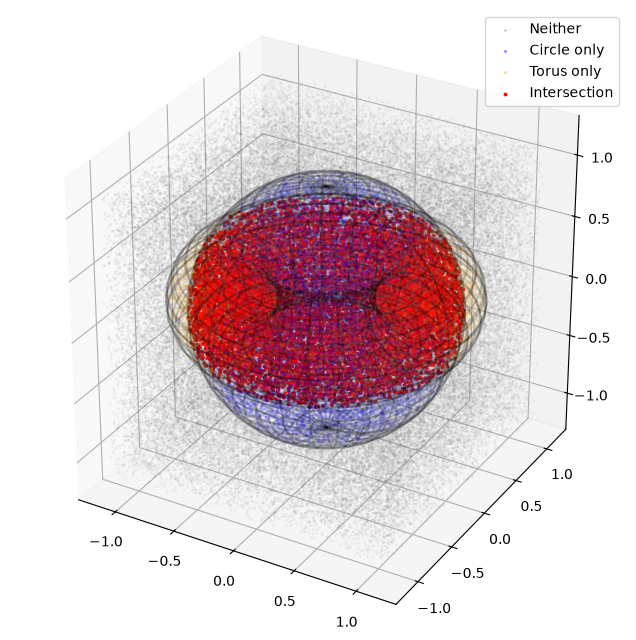

In [56]:
import matplotlib.pyplot as plt

def visualize_system(samples, k, R, r, offset=(0, 0, 0)):
    x0, y0, z0 = offset
    circle = np.sum(samples**2, axis=1) <= k**2
    torus = (np.hypot(samples[:, 0] - x0, samples[:, 1] - y0) - R)**2 + (samples[:, 2] - z0)**2 <= r**2

    fig = plt.figure(figsize=(10, 8))
    ax = fig.add_subplot(projection="3d")
    u, v = np.meshgrid(np.linspace(0, 2*np.pi, 60), np.linspace(0, np.pi, 30))

    ax.plot_wireframe(k*np.sin(v)*np.cos(u), k*np.sin(v)*np.sin(u), k*np.cos(v), color="black", alpha=0.2)
    v = np.linspace(0, 2*np.pi, 30)[:, None]
    ax.plot_wireframe(x0 + (R+r*np.cos(v))*np.cos(u), y0 + (R+r*np.cos(v))*np.sin(u), z0 + r*np.sin(v)*np.ones_like(u), color="black", alpha=0.2)

    # half = R + r
    # X, Y = np.meshgrid([-half, half], [-half, half])
    # for sign in (-1, 1):
    #     ax.plot_wireframe(X, Y, np.full_like(X, sign * half), color="black", alpha=0.2)
    #     ax.plot_wireframe(X, np.full_like(X, sign * half), Y, color="black", alpha=0.2)
    #     ax.plot_wireframe(np.full_like(X, sign * half), X, Y, color="black", alpha=0.2)

    for  mask,             alpha, size, color, label in [
        (~circle & ~torus, 0.3,   1, "gray", "Neither"),
        (circle & ~torus,  0.3,   2, "blue", "Circle only"),
        (~circle & torus,  0.3,   2, "orange", "Torus only"),
        (circle & torus,   1.0,   3, "red", "Intersection"),
    ]:
        ax.scatter(*samples[mask].T, alpha=alpha, s=size, c=color, label=label)

    ax.set_box_aspect((1, 1, 1))
    ax.legend()
    plt.show()

np.random.seed(42)
samples = np.random.uniform(-R-r, R+r, (n, 3))
visualize_system(samples, k, R, r, offset)

In [57]:
n = 10000
k = 1
R = .75
r = .4

area_estimate, data = estimate_monte_carlo(k, R, r, n, sample_method='uniform', log=True, seed=2)
print(data.shape)

(10000,)


1.8433004999999996


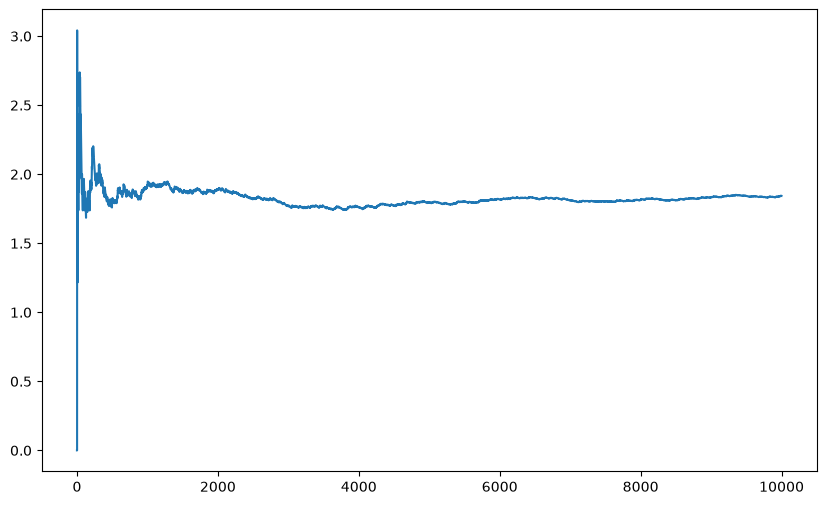

In [58]:
fig, ax = plt.subplots(1, 1, figsize=(10, 6))
bbox_size = 2 * (R + r)
normalized_data = data / (np.arange(data.shape[0])+1) * bbox_size**3
print(area_estimate)

# print((np.arange(data.shape[0])+1)[:10])

ax.plot(normalized_data)

plt.show()

(5, 10000)


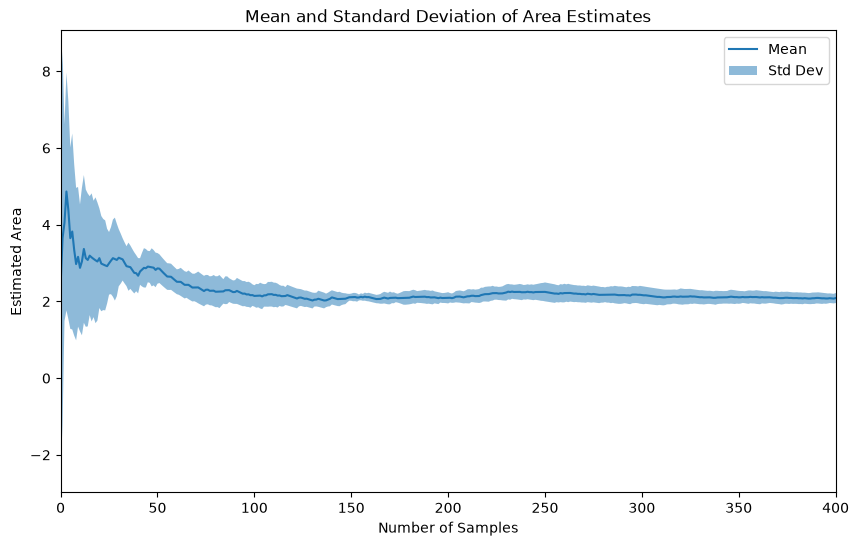

In [59]:
n_runs = 5
runs = np.zeros(shape=(n_runs,n))

def visualize_standard_deviation(runs, bbox_volume, x_lim=None, y_lim=None):
    print(runs.shape)
    std_dev = np.std(runs, axis=0)
    mean = np.mean(runs, axis=0)
    normalized_std_dev = std_dev / (np.arange(runs.shape[1])+1) * bbox_volume
    normalized_mean = mean / (np.arange(runs.shape[1])+1) * bbox_volume

    fig, ax = plt.subplots(1, 1, figsize=(10, 6))
    ax.plot(normalized_mean, label='Mean')
    ax.fill_between(np.arange(runs.shape[1]), normalized_mean - normalized_std_dev, normalized_mean + normalized_std_dev, alpha=0.5, label='Std Dev')
    ax.set_title('Mean and Standard Deviation of Area Estimates')
    ax.set_xlabel('Number of Samples')
    ax.set_ylabel('Estimated Area')
    ax.legend()
    if x_lim is not None:
        ax.set_xlim(x_lim)
    if y_lim is not None:
        ax.set_ylim(y_lim)
    return ax

for i, seed in enumerate(range(1000, 1000 + n_runs)):
    area_estimate, data = estimate_monte_carlo(k, R, r, n, sample_method='uniform', log=True, seed=seed)
    runs[i] = data


visualize_standard_deviation(runs, bbox_size**3, x_lim=(0, 400))
    
plt.show()

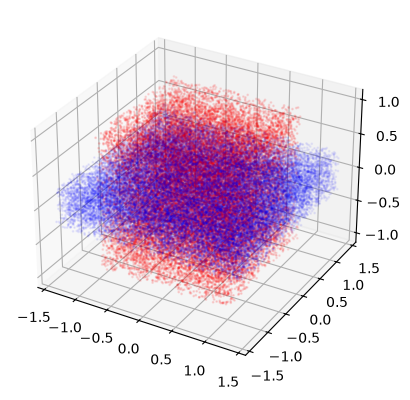

In [60]:
n = 30000
k = 1
R = 1.1
r = .3


bbox_circle_radius = k
bbox_torus_width = 2 * (R + r)
bbox_torus_height = 2 * r

samples_circle = np.random.uniform(-bbox_circle_radius, bbox_circle_radius, size=(n, 3))

samples_torus = np.hstack((np.random.uniform(-bbox_torus_width / 2, bbox_torus_width / 2, size=(n, 2)), np.random.uniform(-bbox_torus_height / 2, bbox_torus_height / 2, size=(n, 1))))

fig = plt.figure()
ax = fig.add_subplot(projection='3d')
ax.scatter(samples_torus[:, 0], samples_torus[:, 1], samples_torus[:, 2], s=1, alpha=0.3, c='blue', label='Torus Samples')
ax.scatter(samples_circle[:, 0], samples_circle[:, 1], samples_circle[:, 2], s=1, alpha=0.4, c='red', label='Circle Samples')


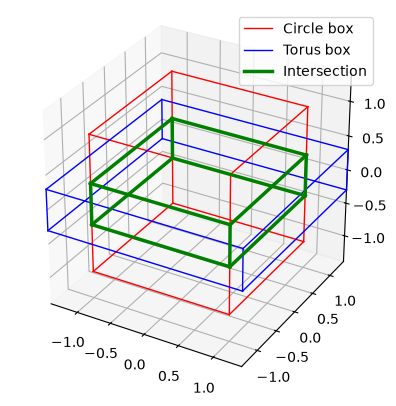

In [61]:
import matplotlib.pyplot as plt

fig = plt.figure()
ax = fig.add_subplot(projection="3d")

for width, height, color, label, line_width in [
    (2 * bbox_circle_radius, 2 * bbox_circle_radius, "red", "Circle box", 1),
    (bbox_torus_width, bbox_torus_height, "blue", "Torus box", 1),
    (2 * min(bbox_circle_radius, bbox_torus_width / 2), 2 * min(bbox_circle_radius, bbox_torus_height / 2), "green", "Intersection", 2.5),
]:
    w, h = width / 2, height / 2
    first = True
    for x in (-w, w):
        for y in (-w, w):
            ax.plot([x, x], [y, y], [-h, h], color=color, linewidth=line_width, label=label if first else "_nolegend_")
            first = False
        for z in (-h, h):
            ax.plot([x, x], [-w, w], [z, z], color=color, linewidth=line_width)
    for y in (-w, w):
        for z in (-h, h):
            ax.plot([-w, w], [y, y], [z, z], color=color, linewidth=line_width)

limit = max(bbox_circle_radius, bbox_torus_width / 2)
ax.set(xlim=(-limit, limit), ylim=(-limit, limit), zlim=(-limit, limit))
ax.set_box_aspect((1, 1, 1))
ax.legend()
plt.show()

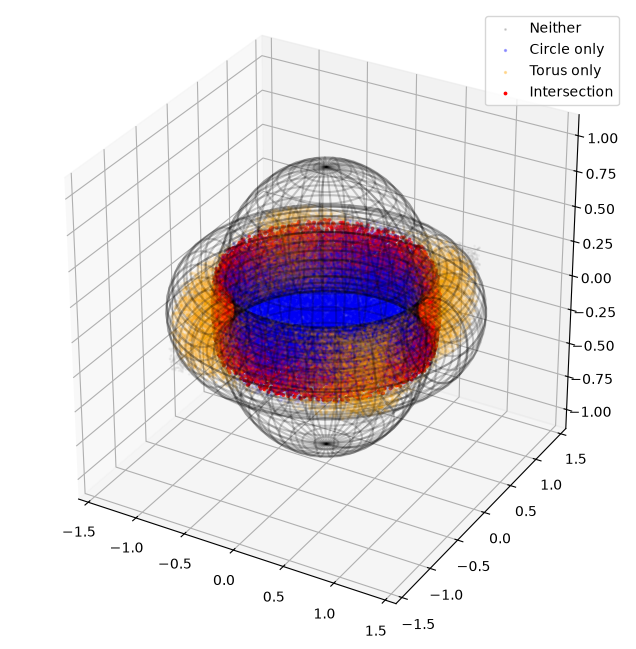

In [62]:

bbox_optimal_height = np.min([k, r])
bbox_optimal_width = np.min([k, R + r])

n = 100000
samples = np.hstack((
    np.random.uniform(-bbox_optimal_width, bbox_optimal_width, size=(n, 2)),
    np.random.uniform(-bbox_optimal_height, bbox_optimal_height, size=(n, 1))
))


visualize_system(samples, k, R, r, offset=(0, 0, 0))


(5, 100000, 3)
(5, 100000)
(5, 10000)


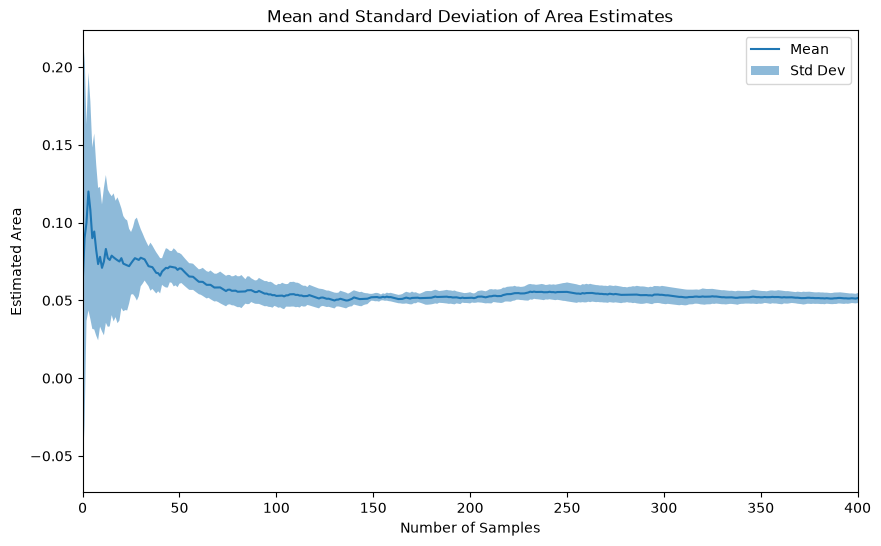

In [63]:
n = 100_000
all_samples = np.zeros((n_runs, n, 3))
print(all_samples.shape)

for i in range(n_runs):
    all_samples[i] = np.hstack((
        np.random.uniform(-bbox_optimal_width, bbox_optimal_width, size=(n, 2)),
        np.random.uniform(-bbox_optimal_height, bbox_optimal_height, size=(n, 1))
    ))

bbox_volume = bbox_optimal_width**2 * bbox_optimal_height

# test_run, test = estimate_monte_carlo_explicit_samples(k, R, r, samples, bbox_optimal_width**2 * bbox_optimal_height, log=True, seed=42)
# print(test.shape)
data = np.array([estimate_monte_carlo_explicit_samples(k, R, r, samples, bbox_volume, log=True, seed=42)[1] for samples in all_samples])
print(data.shape)
# break

visualize_standard_deviation(runs, bbox_optimal_width**2 * bbox_optimal_height, x_lim=(0, 400))
plt.show()